In [23]:
# multi class classification of FGL sources using tree categories
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
from astropy.io import fits
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

import os
import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.24.3


In [24]:
if 1:
    import importlib
    importlib.reload(util);
    importlib.reload(putil);


In [25]:

def get_max_nodes_classes(dct, nsrc_df, max_depth=None):
    res = {}
    tree = list(dct.keys())
    max_nodes = []
    if max_depth is not None:
        max_nodes = [node for node in tree if len(node) == max_depth + 1]
    if len(max_nodes) == 0 or max_depth is None:
        max_nodes = [tree[i] for i in util.get_max_nodes(tree)]
    for node in max_nodes:
        cl = nsrc_df.loc[dct[node]['classes']].sort_values('n').index[-1]
        res[cl] = node
    return res

def get_class_diff(cl, max_cls_dict, nsrc_df, labels=None, one_column=False):
    
    clss = {}
    all_cls = []
    if one_column:
        nclm = 1
    else:
        nclm = 2
    for i in range(nclm):
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            clss[i] = roc_dict[i][node]['classes']
            all_cls.extend(roc_dict[i][node]['classes'])

    all_cls = list(set(all_cls))
    data = np.zeros((len(all_cls), nclm), dtype=int)
    if one_column:
        columns = ['nsrc']
    elif labels is None:
        columns = [0, 1]
    else:
        columns = labels
        
    df = pd.DataFrame(index=all_cls, data=data, columns=columns)
    for i in range(nclm):
        if cl in max_cls_dict[i]:
            df[columns[i]].loc[clss[i]] = nsrc_df['n'].loc[clss[i]]
    df['sum'] = np.sum(df, axis=1)
    df.sort_values('sum', ascending=False, inplace=True)
    
    return df[columns]

In [40]:
script_fn = 'fermi_multiclass/notebooks/compare_perf.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}


plots_folder = '../plots/comparisons/'
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/plots/'

save_plots = 1
save_png = 0
copy2tex = 0
max_depth = 4 #3 # None


#case1 = '4FGL-DR4_2class_RF_wt'
#case2 = '4FGL-DR4_2class_RF_w'

#case1 = '4FGL-DR4_GMM_NN_wt'
#case2 = '4FGL-DR4_GMM_NN_w'


case1 = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' # 47 train/test splits
case2 = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_NN' # 47 train/test splits

one_column = True
add_nsrc = False

if case1.find('2class') > -1 and case2.find('2class') > -1:
    two_class = True
else:
    two_class = False


cat_name = '4FGL-DR4'
config_folder = '../config/'
if cat_name == '4FGL-DR4':
    if two_class:
        baseline_case = '4FGL-DR4_2class_RF'
        #baseline_fn = '../config/4FGL-DR4_2class_baseline.yaml'
    else:
        #baseline_case = '4FGL-DR4_GMM_RF'
        baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
        #baseline_fn = None
    bcase1 = baseline_case
    bcase2 = baseline_case
elif cat_name == '4FGL-DR3':
    case1 = '4FGL-DR3_3class_RF'
    bcase1 = '4FGL-DR3_3class_RF'
    
    case2 = '4FGL-DR3_3class_NN'
    bcase2 = '4FGL-DR3_3class_RF'

cases = [case1, case2]
baseline_cases = [bcase1, bcase2]
labels_dict = {'4FGL-DR4_GMM_RF' : 'RF',
               '4FGL-DR4_GMM_RF_w' : 'wRF',
               '4FGL-DR4_GMM_RF_wt' : 'wtRF',
               '4FGL-DR4_GMM_NN' : 'NN',
               '4FGL-DR4_GMM_NN_w' : 'wNN',
               '4FGL-DR4_GMM_NN_wt' : 'wtNN',
               '4FGL-DR4_2class_RF' : '2-class',
               '4FGL-DR4_2class_RF_w' : 'weighted 2-class',
               '4FGL-DR4_2class_RF_wt' : 'weighted test 2-class',
               '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp': 'RF',
               '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_NN': 'NN'
              }

alg_descr = []
for i in range(2):
    conf_dict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_cases[i], 
                             #baseline_fn=baseline_fn,
                             #cases_fn=cases_fn,
                             case=cases[i], 
                             folder=config_folder)
    if 0:
        conf_dict = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case, 
                             baseline_fn=baseline_fn,
                             folder=config_folder)

    alg_descr.append(util.get_alg_descr(conf_dict))

alg_descr1, alg_descr2 = alg_descr

labels = [labels_dict.get(case, case) for case in cases]

ns_tot = {lb:0 for lb in labels}
if two_class:
    titles = ['AGNs', 'Galactic']
    paper_folder += 'two_class/'
else:
    titles = None
    paper_folder += 'mclass_compare/'

if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)
if not os.path.isdir(paper_folder):
    os.mkdir(paper_folder)

roc_dict = {}
pr_dict = {}
cal_dict = {}
for i in range(2):
    folder = '../data_out/results_%s/' % alg_descr[i]
    roc_dict[i] = dio3.loaddict(folder + 'roc_dict.yaml')
    pr_dict[i] = dio3.loaddict(folder + 'pr_dict.yaml')
    cal_dict[i] = dio3.loaddict(folder + 'cal_dict.yaml')

# use case2 for nsrc_dict and nsrc_df
xdf_fn = util.get_xdf_fn(conf_dict)
xdf = pd.read_csv(xdf_fn, index_col=0)
nsrc_dict = util.get_nsrc_dict(xdf)
nsrc_df = util.nsrc_dict2df(nsrc_dict)

In [41]:
# compare ROCs
max_cls_dict = {}
for i in range(2):
    max_cls_dict[i] = get_max_nodes_classes(roc_dict[i], nsrc_df, max_depth=max_depth)
max_classes = [cl for cl in max_cls_dict[0].keys() if cl in max_cls_dict[1]]
max_classes.extend([cl for cl in max_cls_dict[0].keys() if cl not in max_cls_dict[1]])
max_classes.extend([cl for cl in max_cls_dict[1].keys() if cl not in max_cls_dict[0]])


In [42]:
max_cls_dict

{0: {'fsrq': '0000',
  'bll': '0010',
  'psr': '0100',
  'snr': '0110',
  'msp': '0111'},
 1: {'fsrq': '0000',
  'bll': '0010',
  'psr': '0100',
  'snr': '0110',
  'msp': '0111'}}

In [43]:
if 0:
    max_depth = 4
    tree = list(roc_dict[0].keys())
    max_nodes = [node for node in tree if len(node) == max_depth + 1]
    #max_nodes = [tree[i] for i in util.get_max_nodes(tree)]
    max_nodes

In [44]:
alg_descr

['4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15',
 '4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_NN_layers_20_10']

In [45]:
two_class

False

In [46]:
max_classes

['fsrq', 'bll', 'psr', 'snr', 'msp']

In [47]:
single_plot_pars = {}
if len(max_classes) < 3:
    ncols = 2
else:
    ncols = 3
nrows = int(np.ceil(1. * len(max_classes) / ncols))


if two_class:
    fig_height = 4   # height in inches
    fig_width = 10  # width in inches
    #all_plots_pars = {'axes.titlesize':18}
    all_plots_pars = {'bottom':0.15, 'left':0.1, 'right':0.97, 'axes.titlesize':18}
    fig_size =  [fig_width, fig_height]
    all_plots_pars['fig_size'] = fig_size
    all_plots_pars['font.size'] = 12
    all_plots_pars['legend.fontsize'] = 12
    
else:
    fig_height = 2.5 * nrows + 2   # height in inches
    fig_width = 3 * ncols + 2  # width in inches

    #all_plots_pars = {'axes.titlesize':18}
    all_plots_pars = {'bottom':0.1, 'left':0.08, 'right':0.97, 'axes.titlesize':18}
    fig_size =  [fig_width, fig_height]
    all_plots_pars['fig_size'] = fig_size
    all_plots_pars['font.size'] = 11
    all_plots_pars['legend.fontsize'] = 11
putil.setup_figure_pars(pars_dict=all_plots_pars)
colors = pyplot.rcParams['axes.prop_cycle'].by_key()['color']
print(ncols, nrows)
#putil.setup_figure_pars(pars_dict=single_plot_pars)

3 2


In [48]:
ncols

3

In [49]:
max_cls_dict

{0: {'fsrq': '0000',
  'bll': '0010',
  'psr': '0100',
  'snr': '0110',
  'msp': '0111'},
 1: {'fsrq': '0000',
  'bll': '0010',
  'psr': '0100',
  'snr': '0110',
  'msp': '0111'}}

In [50]:
max_classes

['fsrq', 'bll', 'psr', 'snr', 'msp']

save figure to file: ../plots/comparisons//ROC_comparison_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_NN_layers_20_10_depth4.pdf


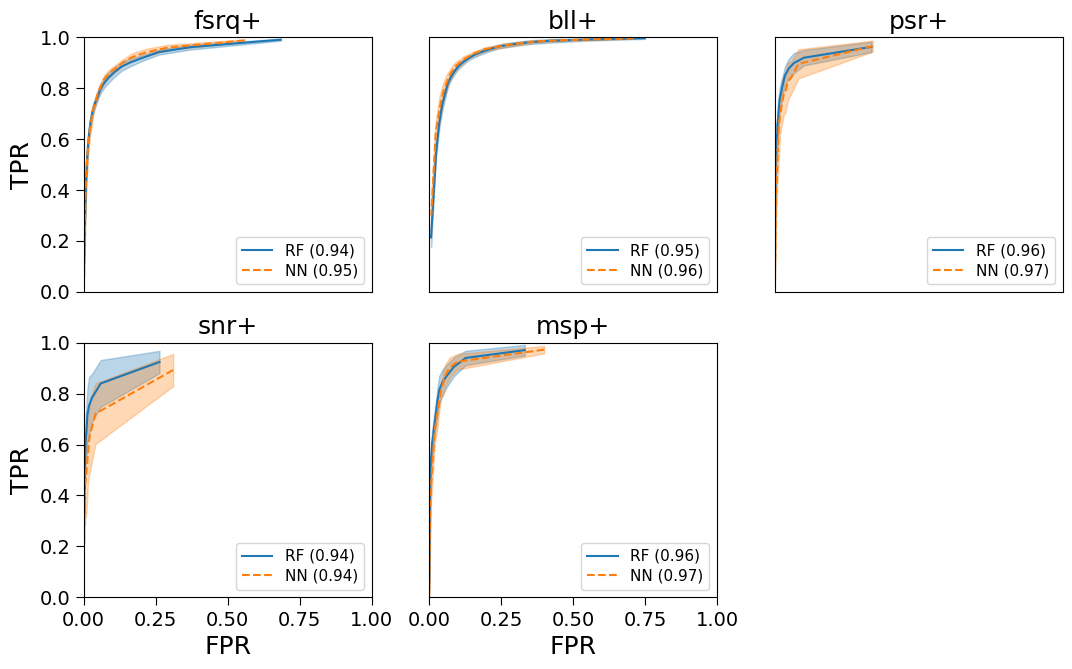

In [51]:
lss = ['-', '--']
#check_class = 'msp'
check_class = None

auc_dict = {lb:1. for lb in labels}
pyplot.figure()
for ind, cl in enumerate(max_classes[:]):
    cind = -1
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    #ax = pyplot.subplot(111)
    #print(cl)
    df = get_class_diff(cl, max_cls_dict, nsrc_df, labels=labels, one_column=one_column)
    #print(df)
    #print()
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            fpr = np.array(roc_dict[i][node][len(node) - 2]['FPR'])
            tpr = np.array(roc_dict[i][node][len(node) - 2]['TPR'])
            tpr_std = np.array(roc_dict[i][node][len(node) - 2]['TPR_STD'])
            auc = roc_dict[i][node][len(node) - 2]['AUC']
            auc_dict[labels[i]] *= auc
            cls = roc_dict[i][node]['classes']
            ns = int(np.sum(nsrc_df.loc[cls]).iloc[0])
            ns_tot[labels[i]] += ns
            if cl == check_class:# and i == 1:
                print(i, cl)
                if i == 0:
                    cdict = {}
                cdict[i] = {}
                #print('FPR', fpr)
                #print('TPR', tpr)
                cdict[i]['FPR'] = fpr
                cdict[i]['TPR'] = tpr
                cdict[i]['auc'] = auc
                #print(roc_dict[i][node][len(node) - 2].keys())

            #print(roc_dict[i][node])
            #print(nsrc_df.loc[cls].sort_values('n', ascending=False))
            label = labels[i] + ' (%.2f)' % auc
            pyplot.plot(fpr, tpr, c=colors[cind], ls=lss[i], label=label)
            pyplot.fill_between(fpr, tpr - tpr_std, tpr + tpr_std, 
                                color=colors[cind], alpha=0.3)
    
    if 1:
        pyplot.legend(loc='lower right', labelspacing=0.3, #fontsize=10
                     )
    elif ind > 2:
        pyplot.legend(loc=(0.5, 0.6), #fontsize=10
                     )
    elif ind == 2:
        pyplot.legend(loc=(0.5, 0.75), #fontsize=10
                     )
    else:
        pyplot.legend(loc=(0.5, 0.7), #fontsize=10
                     )
        
    #pyplot.title('%s-like' % cl)
    if titles is None:
        pyplot.title(cl + '+')
    else:
        pyplot.title(titles[ind])
    pyplot.xlabel('FPR')
    pyplot.ylabel('TPR')
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    if ind % 3 != 0:
        ax.axes.yaxis.set_visible(False)

    #txt = df.to_csv().replace(',','\t').expandtabs() # str(df)
    if not two_class and max_depth > 1 and add_nsrc:
        txt = str(df)
        ax.text(0.97, 0.29, txt, #fontsize=10, 
                fontfamily='monospace', 
                horizontalalignment='right', verticalalignment='bottom')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)

if save_plots:
    if two_class:
        fn = '%s/ROC_comparison_%s_%s.pdf' % (plots_folder, alg_descr1, alg_descr2)
    else:
        fn = '%s/ROC_comparison_%s_%s_depth%i.pdf' % (plots_folder, alg_descr1, alg_descr2, max_depth)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and not two_class or case1 == '4FGL-DR4_2class_RF':
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [52]:
def auc_loc(fpr, tpr):
    fpr_ = list(np.sort(fpr))
    fpr_.append(1.)
    fpr_ = np.array(fpr_)
    dx = fpr_[1:] - fpr_[:-1]
    tpr_ = list(np.sort(tpr))
    tpr_.append(1.)
    tpr_ = np.array(tpr_)
    ys = (tpr_[1:] + tpr_[:-1]) / 2.
    return np.sum(ys * dx)
    

In [53]:
if check_class:
    print(cdict)
    for i in range(2):
        auc_test = auc_loc(cdict[i]['FPR'], cdict[i]['TPR'])
        print(i, auc_test, cdict[i]['auc'])

In [54]:
if check_class:
    pyplot.figure()
    for i in range(2):
        nbins = len(cdict[i]['FPR'])
        pyplot.plot(np.linspace(0, 1, nbins), cdict[i]['FPR'], label='FPR %i' %i)
        pyplot.plot(np.linspace(0, 1, nbins), cdict[i]['TPR'], label='TPR %i' %i)
    pyplot.legend()

In [55]:
#cdict

In [56]:
for lb, auc in auc_dict.items():
    print('%s prod AUC = %.4f' % (lb, auc))

RF prod AUC = 0.7838
NN prod AUC = 0.8058


RF fsrq precision at 0.50 thres: 0.85
NN fsrq precision at 0.50 thres: 0.84
RF fsrq recall at 0.50 thres: 0.80
NN fsrq recall at 0.50 thres: 0.82

RF bll precision at 0.50 thres: 0.89
NN bll precision at 0.50 thres: 0.89
RF bll recall at 0.50 thres: 0.92
NN bll recall at 0.50 thres: 0.92

RF psr precision at 0.50 thres: 0.81
NN psr precision at 0.50 thres: 0.74
RF psr recall at 0.50 thres: 0.66
NN psr recall at 0.50 thres: 0.63

RF snr precision at 0.50 thres: 0.86
NN snr precision at 0.50 thres: 0.82
RF snr recall at 0.50 thres: 0.44
NN snr recall at 0.50 thres: 0.41

RF msp precision at 0.50 thres: 0.79
NN msp precision at 0.50 thres: 0.74
RF msp recall at 0.50 thres: 0.64
NN msp recall at 0.50 thres: 0.67

save figure to file: ../plots/comparisons//PR_comparison_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_NN_layers_20_10_depth4.pdf


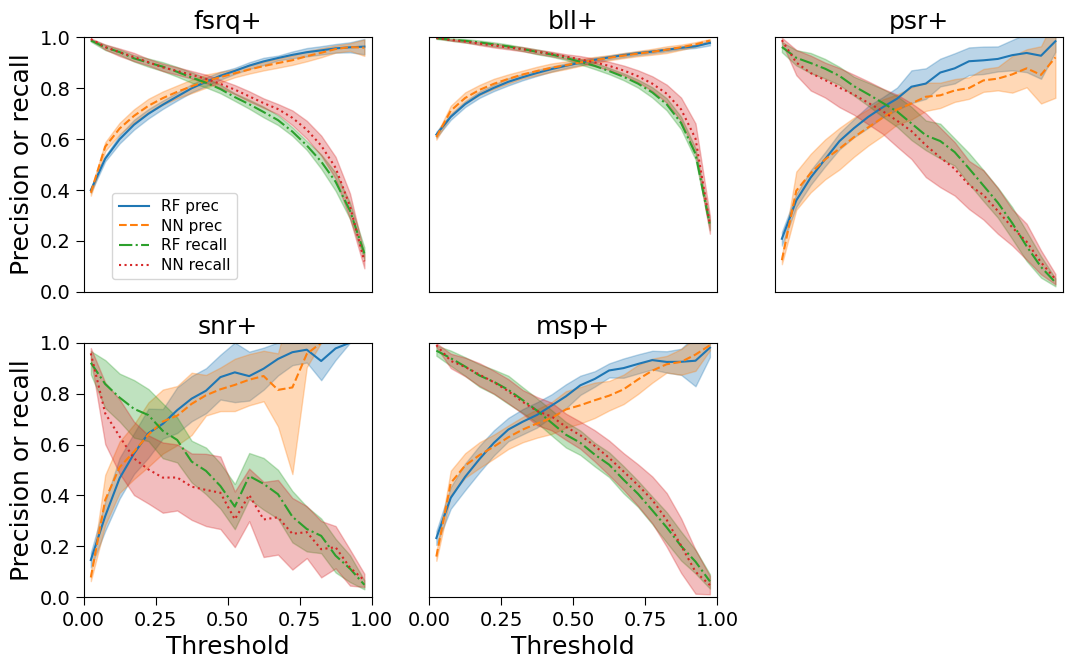

In [57]:
lsp = lss
lsr = ['-.', ':']
#thres_out = [0.25, 0.5, 0.75] # None
thres_out = [0.5]
#thres_out = None


pyplot.figure()
for ind, cl in enumerate(max_classes[:]):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    cind = -1
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            thres_prec = np.array(pr_dict[i][node][len(node) - 2]['thres_prec'])
            prec = np.array(pr_dict[i][node][len(node) - 2]['prec'])
            prec_std = np.array(pr_dict[i][node][len(node) - 2]['prec_std'])
            
            if cl == check_class and i == 1:
                print('Precision', prec)

            #cls = roc_dict[i][node]['classes']
            #ns = int(np.sum(nsrc_df.loc[cls]))
            #ns_tot[labels[i]] += ns
            #label = labels[i] + ' (%i)' % ns
            label = labels[i]
            pyplot.plot(thres_prec, prec, ls=lsp[i], color=colors[cind], 
                        label=label + ' prec')
            pyplot.fill_between(thres_prec, prec - prec_std, prec + prec_std, 
                                color=colors[cind], alpha=0.3)
            
            if thres_out is not None:
                for thres in thres_out:
                    ii = np.argmin(np.abs(thres_prec - thres))
                    print('%s %s precision at %.2f thres: %.2f' % (label, cl, thres, prec[ii]))
        
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            thres_recall = np.array(pr_dict[i][node][len(node) - 2]['thres_recall'])
            recall = np.array(pr_dict[i][node][len(node) - 2]['recall'])
            recall_std = np.array(pr_dict[i][node][len(node) - 2]['recall_std'])
            
            if cl == check_class and i == 1:
                print('Recall (TPR)', recall)

            label = labels[i]
            pyplot.plot(thres_recall, recall, ls=lsr[i], color=colors[cind], 
                        label=label + ' recall')
            pyplot.fill_between(thres_recall, recall - recall_std, recall + recall_std, 
                                color=colors[cind], alpha=0.3)
            if thres_out is not None:
                for thres in thres_out:
                    ii = np.argmin(np.abs(thres_prec - thres))
                    print('%s %s recall at %.2f thres: %.2f' % (label, cl, thres, recall[ii]))

    if thres_out is not None:
        print()
        
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    if ind % 3 != 0:
        ax.axes.yaxis.set_visible(False)
    if ind == 0:
        pyplot.legend(loc=(0.1, 0.05), labelspacing=0.3, #fontsize=10
                     )
    #pyplot.title(cl)
    if titles is None:
        pyplot.title(cl + '+')
    else:
        pyplot.title(titles[ind])
    pyplot.xlabel('Threshold')
    pyplot.ylabel('Precision or recall')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)
if save_plots:
    if two_class:
        fn = '%s/PR_comparison_%s_%s.pdf' % (plots_folder, alg_descr1, alg_descr2)
    else:
        fn = '%s/PR_comparison_%s_%s_depth%i.pdf' % (plots_folder, alg_descr1, alg_descr2, max_depth)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)
    c2t_cond = copy2tex and (conf_dict['sep_model'] != '2class' or case1 == '4FGL-DR4_2class_RF')
    c2t_cond = c2t_cond or (case2 == '4FGL-DR4_RF_NN_w')
    if c2t_cond:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



save figure to file: ../plots/comparisons//cal_comparison_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_NN_layers_20_10_depth4.pdf


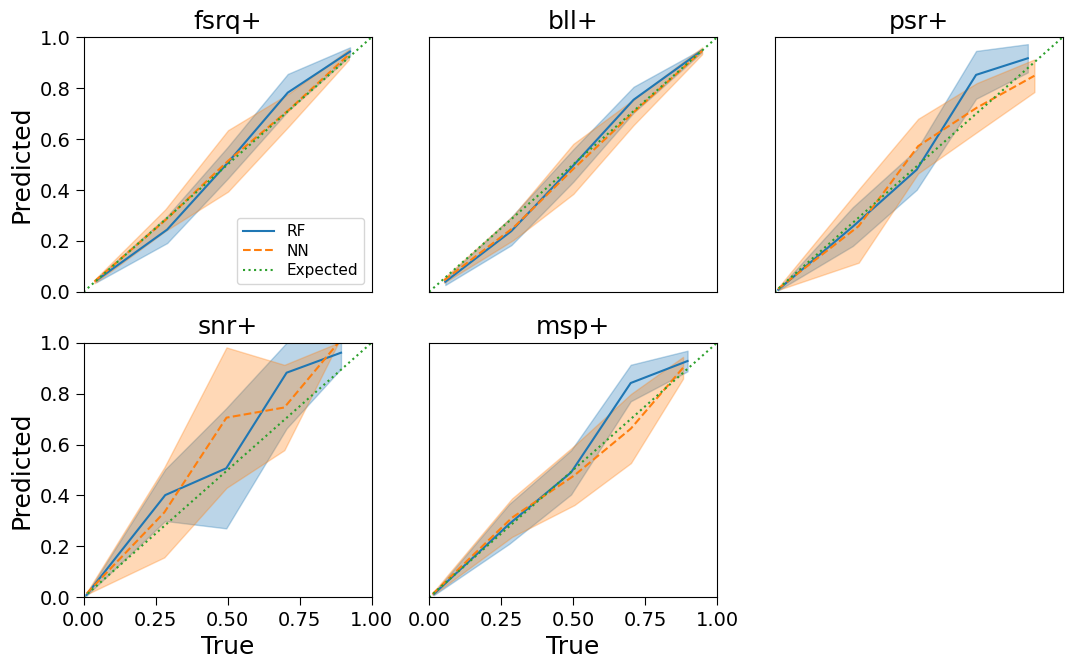

In [58]:

pyplot.figure()
for ind, cl in enumerate(max_classes[:]):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    cind = -1
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            predicted = np.array(cal_dict[i][node][len(node) - 2]['predicted'])
            true = np.array(cal_dict[i][node][len(node) - 2]['true'])
            true_min = np.array(cal_dict[i][node][len(node) - 2]['true_min'])
            true_max = np.array(cal_dict[i][node][len(node) - 2]['true_max'])
            
            label = labels[i]
            pyplot.plot(predicted, true, ls=lsp[i], color=colors[cind], 
                        label=label)
            pyplot.fill_between(predicted, true_min, true_max, 
                                color=colors[cind], alpha=0.3)
    cind += 1
    pyplot.plot([0,1], [0,1], ls=':', color=colors[cind], label='Expected')
    
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    if ind % 3 != 0:
        ax.axes.yaxis.set_visible(False)
    if ind == 0:
        pyplot.legend(loc='lower right', labelspacing=0.3, #fontsize=10
                     )
    #pyplot.title(cl)
    if titles is None:
        pyplot.title(cl + '+')
    else:
        pyplot.title(titles[ind])
    pyplot.xlabel('True')
    pyplot.ylabel('Predicted')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)
if save_plots:
    if two_class:
        fn = '%s/cal_comparison_%s_%s.pdf' % (plots_folder, alg_descr1, alg_descr2)
    else:
        fn = '%s/cal_comparison_%s_%s_depth%i.pdf' % (plots_folder, alg_descr1, alg_descr2, max_depth)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)
    c2t_cond = copy2tex and conf_dict['sep_model'].find('2class') == -1 and case1 == '4FGL-DR4_GMM_RF_wt'
    c2t_cond = c2t_cond or (case2 == '4FGL-DR4_GMM_NN_w')
    if c2t_cond:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

